<a href="https://colab.research.google.com/github/CookOLo/MAT422/blob/main/HW_3_5%2C3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3.5 - K-means

**k-means clustering**: a popular method of vector quantization that aims to partition n observations into k clusters in which each observation belongs to the cluster with the nearest mean (cluster centers or cluster centroid), serving as a prototype of the cluster
- tries to minimize **within-cluster sum of squares (WCSS)** -- variance; the squared distance of each vector from its centroid summed over all vectors

$$WCSS_i = \sum _{x∈S_i} || x - μ(S_i)||^2$$

where $μ(S_i)$ is the mean of points in $S_i$

$$μ(S_i) = \frac{1} {|S|} \sum_{x∈S} x$$

The objective is to find:
$$arg\;min_s\;\sum^k_{i=1}WCSS_i$$

K-means Clustering Algorithm:
1. Cluster teh data into k groups where k is predefined
2. Select k points at random as cluster centers
3. Assign objects to their closest cluster center according to the Euclidean distance function (if 2D, then that's Pygatheroem Function)
4. Calculate the centroid or mean of all objects in each cluster
5. Repeat steps 3 and 4 until the same points are assigned to each cluster in consecutive rounds



In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

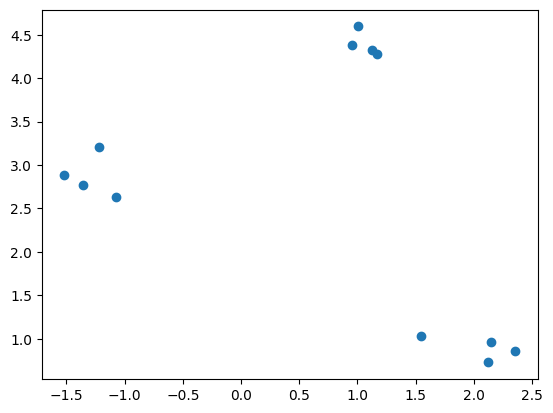

In [16]:
# Clusters are being made
## 3 clusters, 12 points
X, y = make_blobs(n_samples = 12, centers = 3, cluster_std = 0.20, random_state = 0)
plt.scatter(X[:, 0], X[:, 1])

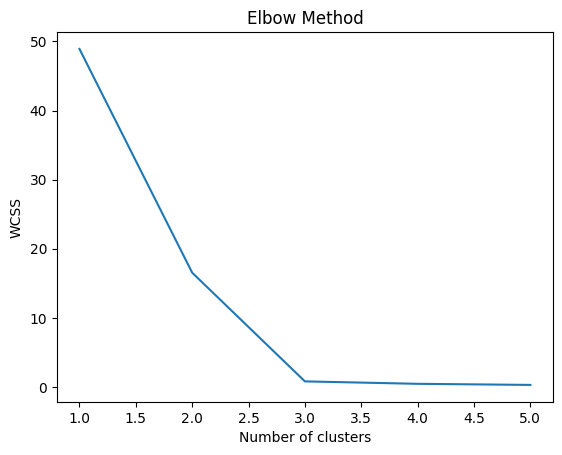

It looks like k=3 is the most optimal amount of clusters we should be looking for!


In [20]:
# To deterimine K (the number of clusters we want to identiy)
## On one hand, we can visually look at the graph
## On the other hand, we can use the Elbow method to indicate the k, looking at the x-value in which the slope starts to level out
wcss = []

for i in range(1, 6):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=900, n_init=10, random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 6), wcss)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

print("It looks like k=3 is the most optimal amount of clusters we should be looking for!");

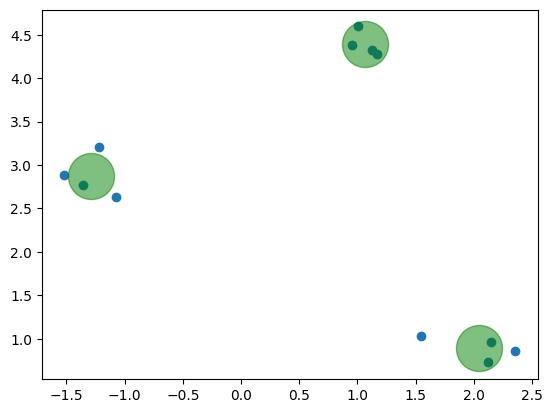

Green indicates clusters that are identified what k-means identifies as clusters after a great amount of iterations


In [29]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=900, n_init=10, random_state=0)
pred_y = kmeans.fit_predict(X)
plt.scatter(X[:,0], X[:,1])
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=1100, c='green', alpha = 0.5)
plt.show()

print("Green indicates clusters that are identified what k-means identifies as clusters after a great amount of iterations");

# Supper Vector Machine
**Support-vector machines (SVMs)**: supervised learning models in machine learning, which aims to analyze data for classication and regression analysis
- objective of support vector machine algorithm is to find a hyperplane in a high-diemnsional space of number of features that distinctly classifies the data points

In [31]:
import numpy as np
import cvxopt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix

In [32]:
# Function of SVM
class SVM:
  def fit(self, X, y):
        n_samples, n_features = X.shape

  # P = X^T X
        K = np.zeros((n_samples, n_samples))
        for i in range(n_samples):
            for j in range(n_samples):
                K[i,j] = np.dot(X[i], X[j])

        P = cvxopt.matrix(np.outer(y, y) * K)

  # q = -1 (1xN)
        q = cvxopt.matrix(np.ones(n_samples) * -1)

  # A = y^T
        A = cvxopt.matrix(y, (1, n_samples))

  # b = 0
        b = cvxopt.matrix(0.0)

  # -1 (NxN)
        G = cvxopt.matrix(np.diag(np.ones(n_samples) * -1))

  # 0 (1xN)
        h = cvxopt.matrix(np.zeros(n_samples))

        solution = cvxopt.solvers.qp(P, q, G, h, A, b)

  # Lagrange multipliers
        a = np.ravel(solution['x'])

  # Lagrange have non zero lagrange multipliers
        sv = a > 1e-5
        ind = np.arange(len(a))[sv]
        self.a = a[sv]
        self.sv = X[sv]
        self.sv_y = y[sv]
  # Intercept
        self.b = 0
        for n in range(len(self.a)):
            self.b += self.sv_y[n]
            self.b -= np.sum(self.a * self.sv_y * K[ind[n], sv])
        self.b /= len(self.a)

  # Weights
        self.w = np.zeros(n_features)
        for n in range(len(self.a)):
            self.w += self.a[n] * self.sv_y[n] * self.sv[n]

  def project(self, X):
      return np.dot(X, self.w) + self.b


  def predict(self, X):
      return np.sign(self.project(X))

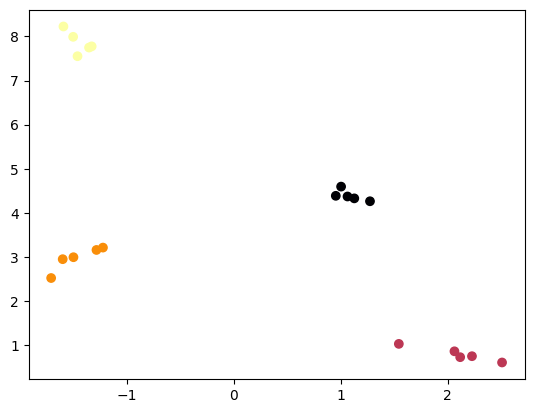

In [50]:
X, y = make_blobs(n_samples=20, centers=4,
                  random_state=0, cluster_std=0.20)
y[y == 0] = -1
tmp = np.ones(len(X))
y = tmp * y

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='inferno')

In [51]:
# Training the data on SVM
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)



svm = SVM()
svm.fit(X_train, y_train)

     pcost       dcost       gap    pres   dres
 0: -7.8409e+00 -1.6811e+01  4e+01  5e+00  2e+00
 1: -2.8622e+01 -2.8715e+01  1e+01  2e+00  1e+00
 2: -2.7049e+01 -2.3926e+01  1e+01  2e+00  8e-01
 3: -1.6825e+01 -1.2925e+01  1e+01  9e-01  4e-01
 4: -7.6942e+00 -8.4137e+00  1e+00  2e-02  1e-02
 5: -7.9780e+00 -7.9872e+00  2e-02  3e-04  1e-04
 6: -7.9824e+00 -7.9825e+00  2e-04  3e-06  1e-06
 7: -7.9824e+00 -7.9824e+00  2e-06  3e-08  1e-08
Optimal solution found.


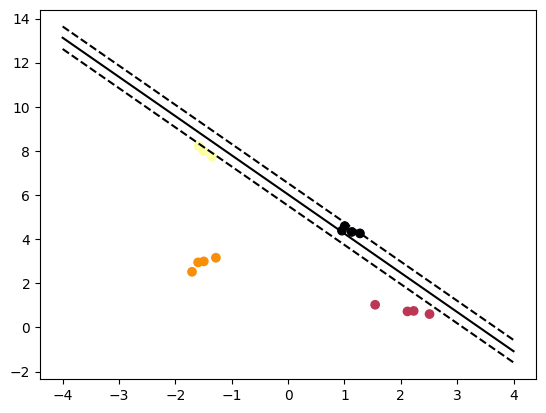

In [53]:
# Representing that in dataset
def f(x, w, b, c=0):
    return (-w[0] * x - b + c) / w[1]

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='inferno')

# w.x + b = 0
a0 = -4; a1 = f(a0, svm.w, svm.b)
b0 = 4; b1 = f(b0, svm.w, svm.b)
plt.plot([a0,b0], [a1,b1], 'k')

# w.x + b = 1
a0 = -4; a1 = f(a0, svm.w, svm.b, 1)
b0 = 4; b1 = f(b0, svm.w, svm.b, 1)
plt.plot([a0,b0], [a1,b1], 'k--')

# w.x + b = -1
a0 = -4; a1 = f(a0, svm.w, svm.b, -1)
b0 = 4; b1 = f(b0, svm.w, svm.b, -1)
plt.plot([a0,b0], [a1,b1], 'k--')